In [1]:
import pandas as pd
import numpy as np

In [2]:
#load the data from Excel file
file_path = '/Users/dr/Documents/GitHub/Deposit_Modeling/Quantitative_Finance_Deposits_Case_Study_Data_2025.xlsx'

In [37]:
# Load FDIC_QBP sheet without header
fdic_full = pd.read_excel(file_path, sheet_name='FDIC_QBP', header=None)

In [8]:
fdic_full.head(10)

,0,1,2,3,4,5,6,7,8,9,...,123,124,125,126,127,128,129,130,131,132
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Assets and Liabilities of FDIC-Insured Commerc...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,(Amounts in $ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,1991Q2,1991Q3,1991Q4,1992Q1,1992Q2,1992Q3,1992Q4,1993Q1,...,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,Non-maturity Interest-bearing deposits,1098276.374,1125986.253,1184866.053,1246734.189,1265699.776,1287788.772,1347926.593,1366617.108,...,10966350.743,11401946.101,11616384.831,11350611.778,11211116.468,11188614.712,10656409.562,10522335.698,10397281.573,10499828.936
8,NaN,Noninterest-bearing deposits,454615.45,475201.761,491843.215,483989.015,496919.561,501131.721,554649.798,498309.375,...,5365297.244,5516235.146,5517936.329,5404246.352,5193729.093,4828136.078,4514530.179,4235865.279,4075738.567,3974993.362
9,NaN,Time deposits,1706710.057,1679959.999,1613051.671,1534806.93,1467776.199,1404153.533,1337713.371,1287128.03,...,1302559.983,1271437.646,1246782.301,1322152.403,1486595.599,1708608.076,2133028.779,2439727.683,2685268.545,2870392.106


In [25]:
# Custom function for quarter parsing
def quarter_to_date(q_str):
    """Convert 'YYYY-QQ' string to end-of-quarter date (e.g., '1976-Q1' -> '1976-03-31')."""
    year, q = q_str.split('-Q')
    month = int(q) * 3
    if month == 3:
        day = 31
    elif month == 6:
        day = 30
    elif month == 9:
        day = 30
    elif month == 12:
        day = 31
    else:
        raise ValueError(f"Invalid quarter in {q_str}")
    return pd.to_datetime(f"{year}-{month:02d}-{day}")

In [26]:
# Find quarter row: Search col2 for '1991Q2' (col0 empty per screenshot)
quarter_mask = fdic_full.iloc[:,2].astype(str).str.contains('1991Q2', na=False)
if not quarter_mask.any():
    raise ValueError("Could not find quarter row starting with '1991Q2' in column 2")
quarter_row_idx = fdic_full[quarter_mask].index[0]
quarters = fdic_full.iloc[quarter_row_idx, 1:].dropna().astype(str).values.tolist()
print("Quarters loaded:", quarters[:5], "...")

Quarters loaded: ['1991Q2', '1991Q3', '1991Q4', '1992Q1', '1992Q2'] ...


In [27]:
# Find data rows: col1 contains 'deposits' (case insensitive)
labels_mask = fdic_full.iloc[:,1].astype(str).str.contains('deposits', na=False, case=False)
data_rows = fdic_full[labels_mask].index.tolist()

if len(data_rows) != 3:
    print("Found rows:", fdic_full.iloc[data_rows,0].values)
    raise ValueError(f"Expected 3 deposit rows, found {len(data_rows)}. Check sheet.")

In [28]:
data_rows

[7, 8, 9]

In [29]:
# Extract series
non_mat_ib = fdic_full.iloc[data_rows[0], 2:2+len(quarters)].values.astype(float)
non_interest = fdic_full.iloc[data_rows[1], 2:2+len(quarters)].values.astype(float)
time_dep = fdic_full.iloc[data_rows[2], 2:2+len(quarters)].values.astype(float)

In [30]:
# Create dates: End-of-quarter ('QE') from 1991Q2
dates = pd.date_range(start='1991-06-30', periods=len(quarters), freq='QE')
print("Date range:", dates[0], "to", dates[-1])

Date range: 1991-06-30 00:00:00 to 2023-12-31 00:00:00


In [31]:
# Build FDIC dataframe
fdic_data = pd.DataFrame({
    'Date': dates,
    'Non_Maturity_IB': non_mat_ib,
    'Non_Interest_Bearing': non_interest,
    'Time_Deposits': time_dep
})
fdic_data.set_index('Date', inplace=True)
fdic_data = fdic_data.dropna(how='all')  # Drop if all NaN
print("FDIC Data Shape:", fdic_data.shape)
print(fdic_data.head())

FDIC Data Shape: (131, 3)
            Non_Maturity_IB  Non_Interest_Bearing  Time_Deposits
Date                                                            
1991-06-30      1098276.374            454615.450    1706710.057
1991-09-30      1125986.253            475201.761    1679959.999
1991-12-31      1184866.053            491843.215    1613051.671
1992-03-31      1246734.189            483989.015    1534806.930
1992-06-30      1265699.776            496919.561    1467776.199


In [32]:
# Load Historical Economic Data with custom parser
historic_raw = pd.read_excel(file_path, sheet_name='2024-Historic_Domestic', header=0)
historic = historic_raw[historic_raw['Scenario Name'] == 'Actual'].copy()
historic['Date'] = historic['Date'].str.replace(r'\s*Q', '-Q', regex=True).str.strip().apply(quarter_to_date)
historic.set_index('Date', inplace=True)
historic = historic.drop(columns=['Scenario Name'])
print("Historic Data Shape:", historic.shape)
print(historic.head())

Historic Data Shape: (192, 21)
            Real GDP  Real GDP growth  Nominal GDP  Nominal GDP growth  \
Date                                                                     
1976-03-31  6323.649              9.3     1820.487                14.0   
1976-06-30  6370.025              3.0     1852.332                 7.2   
1976-09-30  6404.895              2.2     1886.558                 7.6   
1976-12-31  6451.177              2.9     1934.273                10.5   
1977-03-31  6527.703              4.8     1988.648                11.7   

            Real disposable income  Real disposable income growth  \
Date                                                                
1976-03-31             4648.800000                            5.0   
1976-06-30             4675.266667                            2.3   
1976-09-30             4711.766667                            3.2   
1976-12-31             4741.700000                            2.6   
1977-03-31             4752.300000  

In [33]:
# Load Scenarios with custom parser
scenarios_raw = pd.read_excel(file_path, sheet_name='2024-Supervisory_Scenarios', header=0)
scenarios = scenarios_raw.copy()
scenarios['Date'] = scenarios['Date'].str.replace(r'\s*Q', '-Q', regex=True).str.strip().apply(quarter_to_date)
scenarios.set_index(['Scenario Name', 'Date'], inplace=True)
print("Scenarios Shape:", scenarios.shape)

Scenarios Shape: (52, 21)


In [88]:
# Supervisory Baseline Scenario Preview
baseline_scen = scenarios.xs('Supervisory Baseline', level='Scenario Name')
print("Baseline Scenario Preview:")
print(baseline_scen.head())
print(baseline_scen.shape)

Baseline Scenario Preview:
                Real GDP  Real GDP growth   Nominal GDP  Nominal GDP growth  \
Date                                                                          
2024-03-31  22735.953138              1.0  28180.653984                 3.2   
2024-06-30  22775.741055              0.7  28384.963725                 2.9   
2024-09-30  22826.986473              0.9  28604.947194                 3.1   
2024-12-31  22912.587672              1.5  28862.391719                 3.6   
2025-03-31  23015.694317              1.8  29158.231234                 4.1   

            Real disposable income  Real disposable income growth  \
Date                                                                
2024-03-31            16961.584792                            2.5   
2024-06-30            17037.911923                            1.8   
2024-09-30            17114.582527                            1.8   
2024-12-31            17200.155440                            2.0   
2025-

In [34]:
# Merge deposit data with historic data
merged_historic = fdic_data.join(historic, how='inner')
print("Merged Historic Shape:", merged_historic.shape)
print(merged_historic.head())

Merged Historic Shape: (131, 24)
            Non_Maturity_IB  Non_Interest_Bearing  Time_Deposits   Real GDP  \
Date                                                                          
1991-06-30      1098276.374            454615.450    1706710.057  10029.510   
1991-09-30      1125986.253            475201.761    1679959.999  10080.195   
1991-12-31      1184866.053            491843.215    1613051.671  10115.329   
1992-03-31      1246734.189            483989.015    1534806.930  10236.435   
1992-06-30      1265699.776            496919.561    1467776.199  10347.429   

            Real GDP growth  Nominal GDP  Nominal GDP growth  \
Date                                                           
1991-06-30              3.2     6126.862                 6.2   
1991-09-30              2.0     6205.937                 5.3   
1991-12-31              1.4     6264.540                 3.8   
1992-03-31              4.9     6363.102                 6.4   
1992-06-30              4.4  

In [89]:
# Descriptive Statistics
print("\n=== DESCRIPTIVE STATISTICS ===")
print("Deposits Overview:")
print(merged_historic[['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']].describe())
print("\nKey Econ Vars Overview:")
key_econ_vars = ['Real GDP growth', 'Nominal GDP growth', 'Unemployment rate', 'CPI inflation rate',
                 '3-month Treasury rate', '10-year Treasury yield', 'Mortgage rate']
print(merged_historic[key_econ_vars].describe())


=== DESCRIPTIVE STATISTICS ===
Deposits Overview:
       Non_Interest_Bearing  Non_Maturity_IB  Time_Deposits
count          1.310000e+02     1.310000e+02   1.310000e+02
mean           1.888082e+06     4.261717e+06   1.781209e+06
std            1.405839e+06     3.074187e+06   3.905313e+05
min            4.546155e+05     1.098276e+06   1.205898e+06
25%            7.190829e+05     1.524896e+06   1.555535e+06
50%            1.207845e+06     3.051354e+06   1.673622e+06
75%            2.983428e+06     6.141237e+06   1.934110e+06
max            5.517936e+06     1.161638e+07   2.870392e+06

Key Econ Vars Overview:
       Real GDP growth  Nominal GDP growth  Unemployment rate  \
count       131.000000          131.000000         131.000000   
mean          2.633588            4.906107           5.756489   
std           4.561943            5.151441           1.773441   
min         -28.000000          -29.200000           3.500000   
25%           1.550000            3.600000           4.4000

In [40]:
# Growth Rates
merged_historic['Non_IB_Growth'] = merged_historic['Non_Interest_Bearing'].pct_change() * 100
merged_historic['Non_Mat_IB_Growth'] = merged_historic['Non_Maturity_IB'].pct_change() * 100
merged_historic['Time_Growth'] = merged_historic['Time_Deposits'].pct_change() * 100
print("\nDeposit Growth Rates Summary:")
print(merged_historic[['Non_IB_Growth', 'Non_Mat_IB_Growth', 'Time_Growth']].describe())


Deposit Growth Rates Summary:
       Non_IB_Growth  Non_Mat_IB_Growth  Time_Growth
count     130.000000         130.000000   130.000000
mean        1.790456           1.777917     0.496972
std         4.733555           2.313007     4.508313
min       -10.157837          -5.470373   -10.729854
25%        -0.984984           0.391858    -1.906562
50%         1.586641           1.849312     0.148402
75%         4.390249           2.992775     2.092924
max        17.654082           8.759102    24.840144


In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

In [96]:
import os
os.makedirs('plots', exist_ok=True)

In [42]:
# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

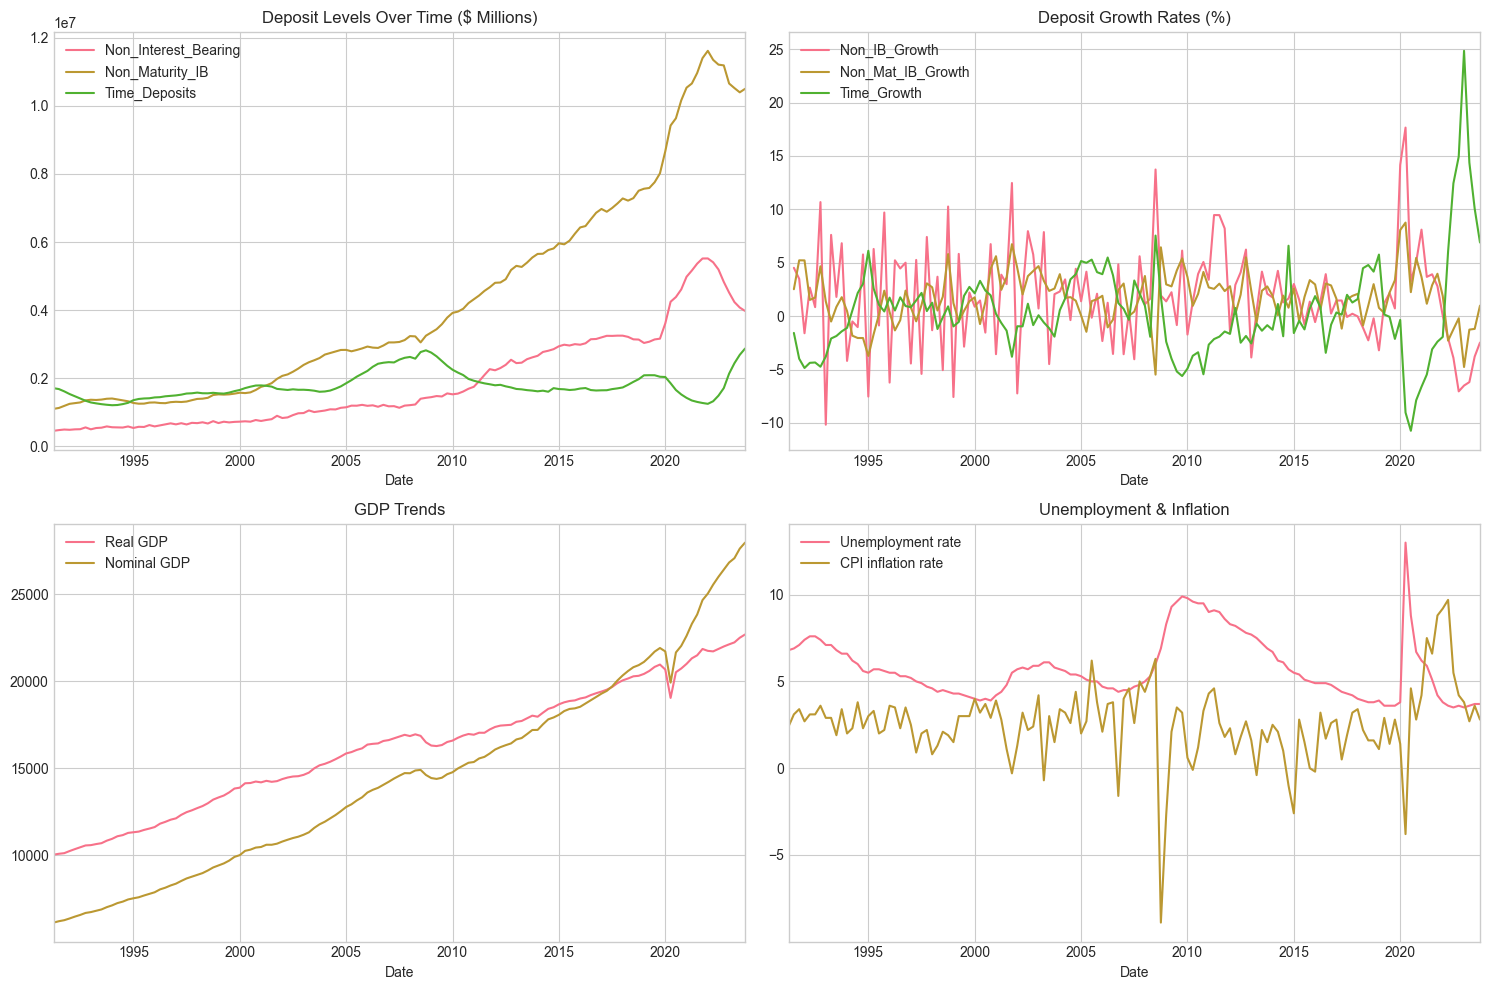

In [97]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
merged_historic[['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']].plot(ax=axes[0,0], title='Deposit Levels Over Time ($ Millions)')
merged_historic[['Non_IB_Growth', 'Non_Mat_IB_Growth', 'Time_Growth']].plot(ax=axes[0,1], title='Deposit Growth Rates (%)')
merged_historic[['Real GDP', 'Nominal GDP']].plot(ax=axes[1,0], title='GDP Trends')
merged_historic[['Unemployment rate', 'CPI inflation rate']].plot(ax=axes[1,1], title='Unemployment & Inflation')
plt.tight_layout()
plt.savefig('plots/deposit_trends.png', dpi=300, bbox_inches='tight')
plt.show()

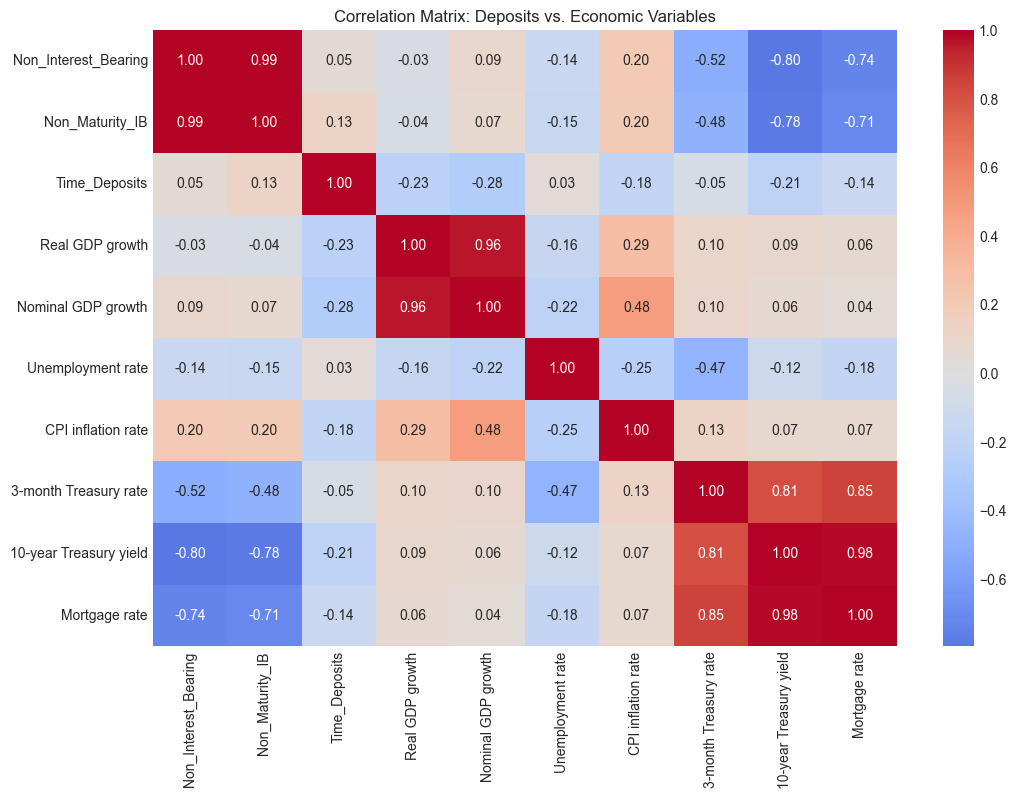

In [98]:
corr_vars = ['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits'] + key_econ_vars
corr_matrix = merged_historic[corr_vars].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix: Deposits vs. Economic Variables')
plt.savefig('plots/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

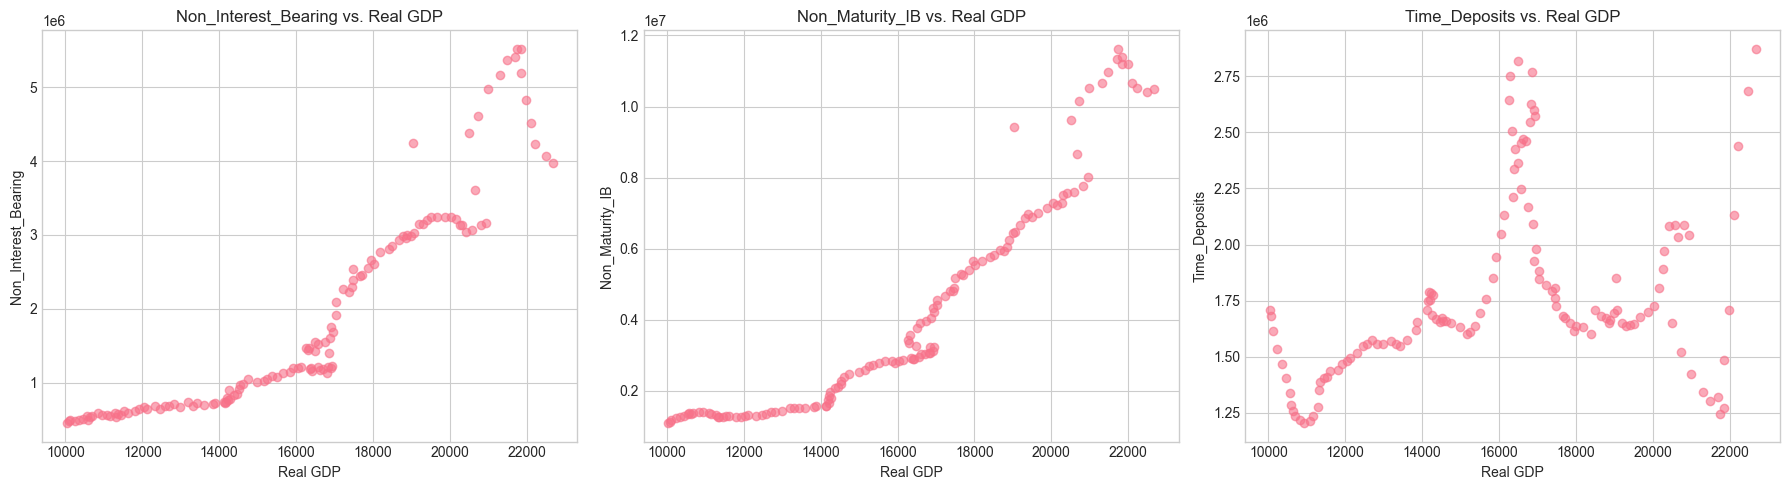

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, dep in enumerate(['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']):
    axes[i].scatter(merged_historic['Real GDP'], merged_historic[dep], alpha=0.6)
    axes[i].set_xlabel('Real GDP')
    axes[i].set_ylabel(dep)
    axes[i].set_title(f'{dep} vs. Real GDP')
plt.tight_layout()
plt.savefig('plots/scatter_gdp_deposits.png', dpi=300, bbox_inches='tight')
plt.show()

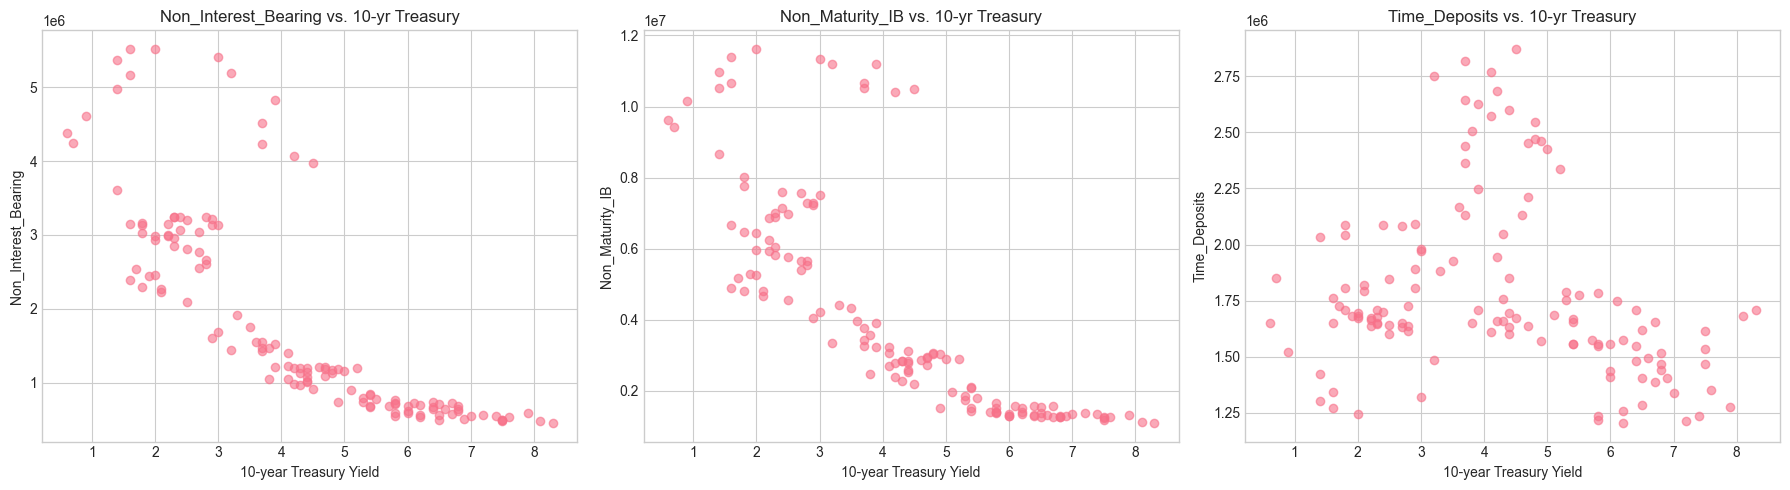

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, dep in enumerate(['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']):
    axes[i].scatter(merged_historic['10-year Treasury yield'], merged_historic[dep], alpha=0.6)
    axes[i].set_xlabel('10-year Treasury Yield')
    axes[i].set_ylabel(dep)
    axes[i].set_title(f'{dep} vs. 10-yr Treasury')
plt.tight_layout()
plt.savefig('plots/scatter_rates_deposits.png', dpi=300, bbox_inches='tight')
plt.show()

In [47]:
from statsmodels.tsa.seasonal import seasonal_decompose

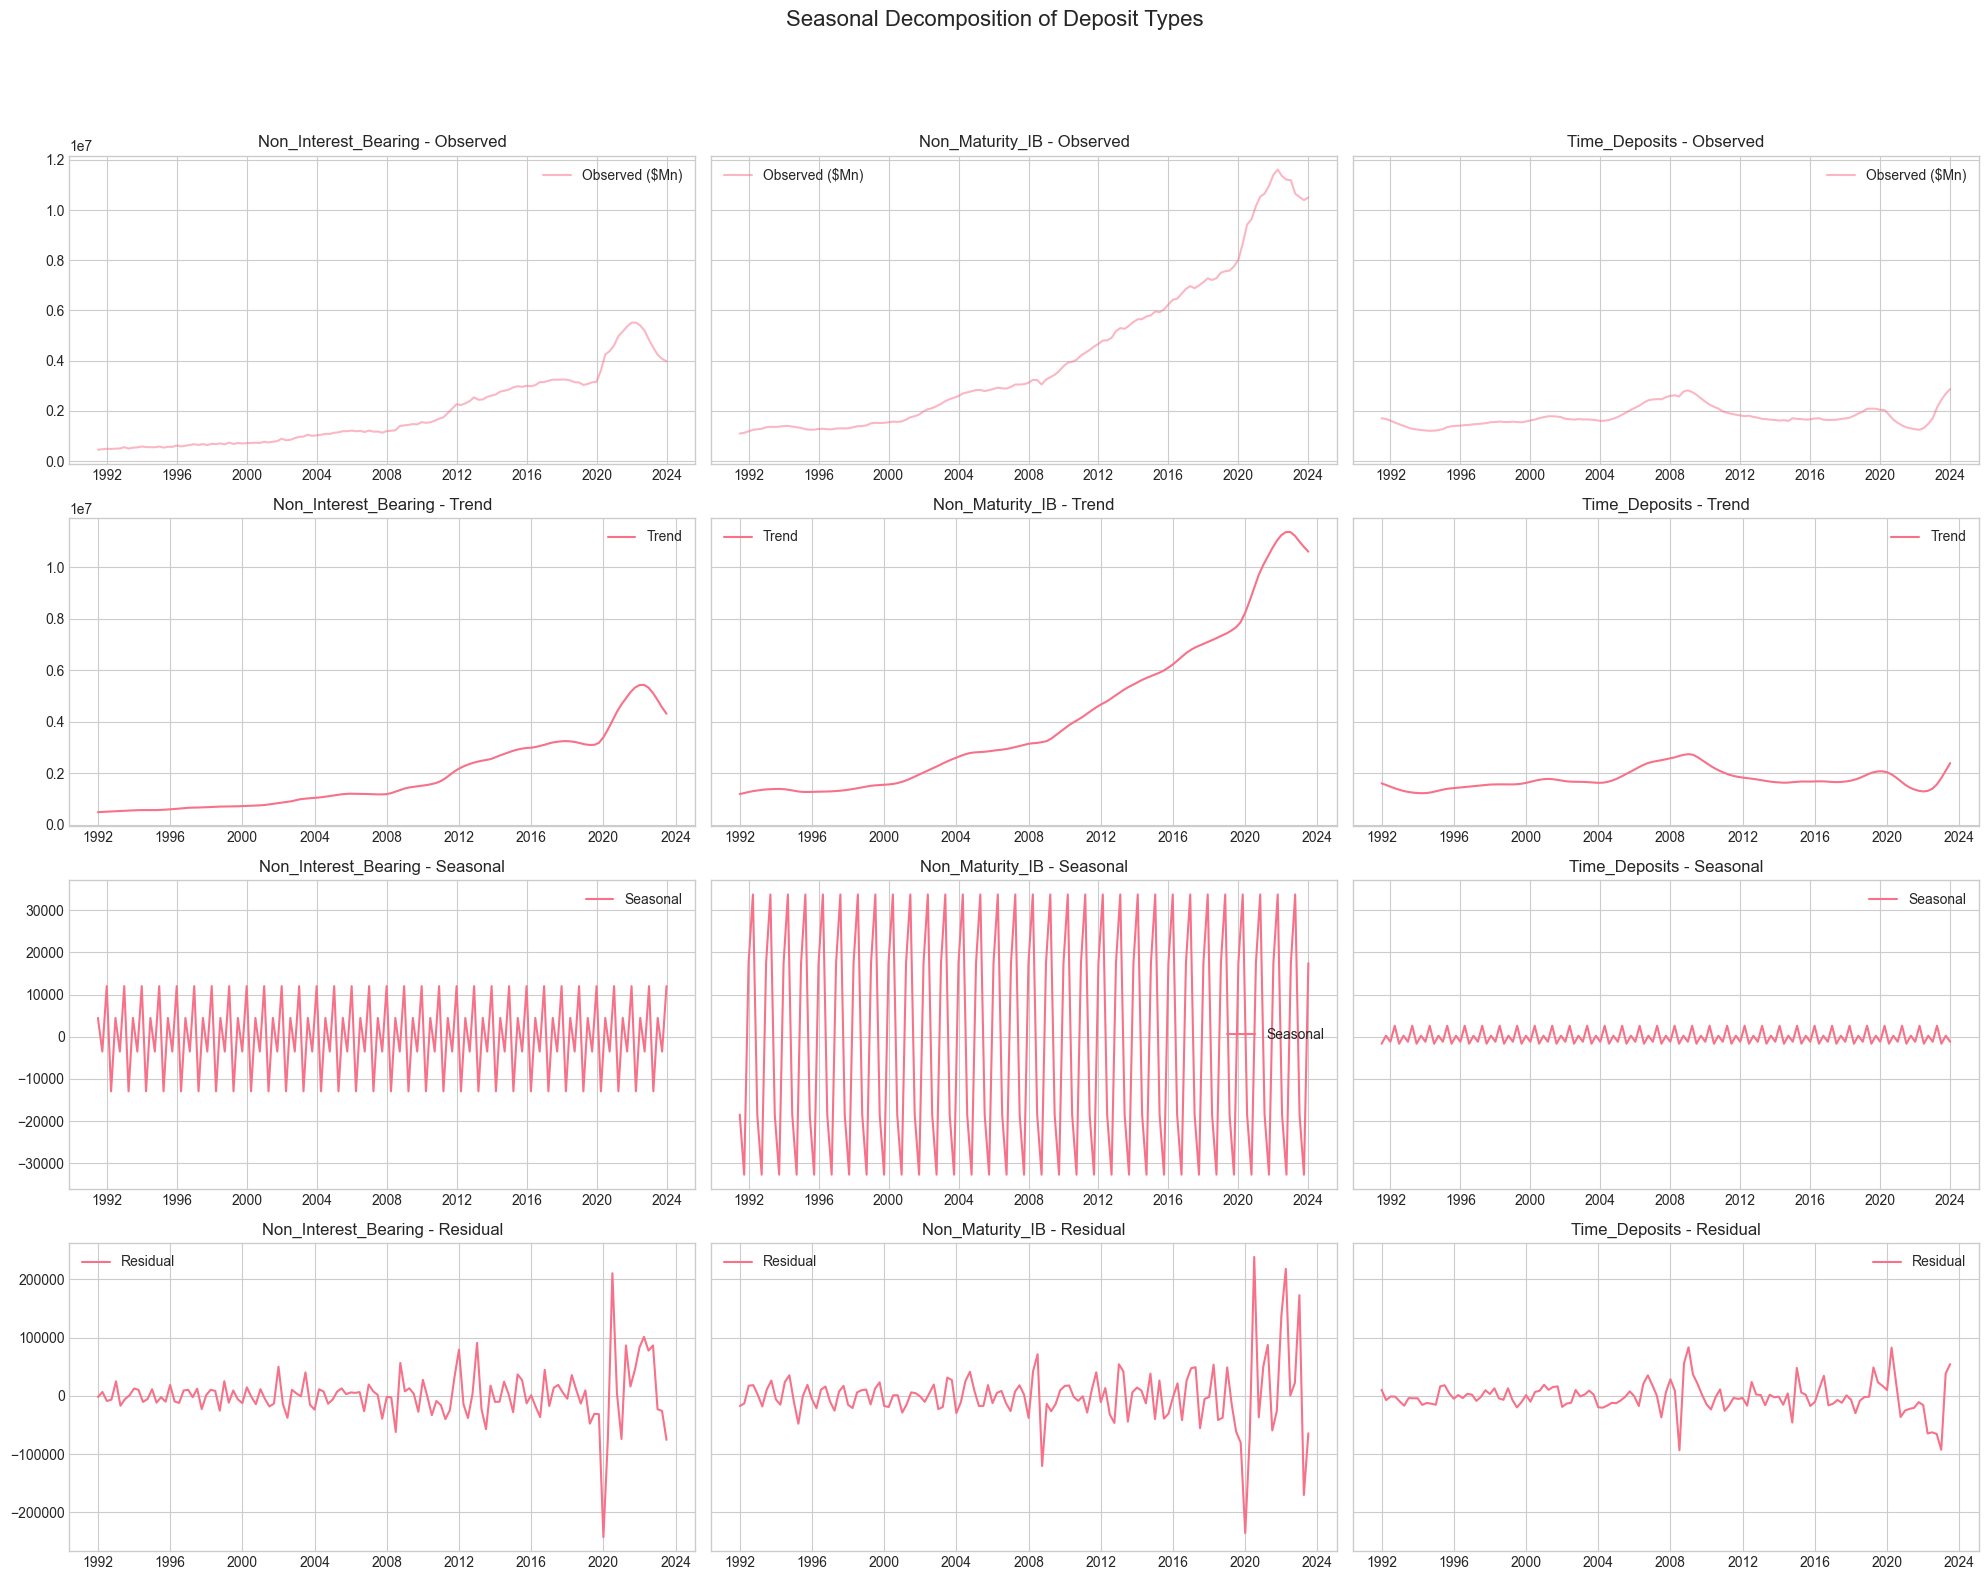

In [101]:
# Seasonal Decomposition
deposit_types = ['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']
fig, axes = plt.subplots(4, 3, figsize=(20, 15), sharey='row')
for i, dep in enumerate(deposit_types):
    decomp = seasonal_decompose(merged_historic[dep].interpolate(), model='additive', period=4)
    axes[0, i].plot(merged_historic.index, merged_historic[dep], label='Observed ($Mn)', alpha=0.5)
    axes[0, i].set_title(f'{dep} - Observed')
    axes[1, i].plot(merged_historic.index, decomp.trend, label='Trend')
    axes[1, i].set_title(f'{dep} - Trend')
    axes[2, i].plot(merged_historic.index, decomp.seasonal, label='Seasonal')
    axes[2, i].set_title(f'{dep} - Seasonal')
    axes[3, i].plot(merged_historic.index, decomp.resid, label='Residual')
    axes[3, i].set_title(f'{dep} - Residual')

    for j in range(4):
        axes[j, i].legend()
fig.suptitle('Seasonal Decomposition of Deposit Types', y=1.05, fontsize=16)
plt.tight_layout()
plt.savefig('plots/seasonal_decomp_all.png', dpi=300, bbox_inches='tight')
plt.show()

In [93]:
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

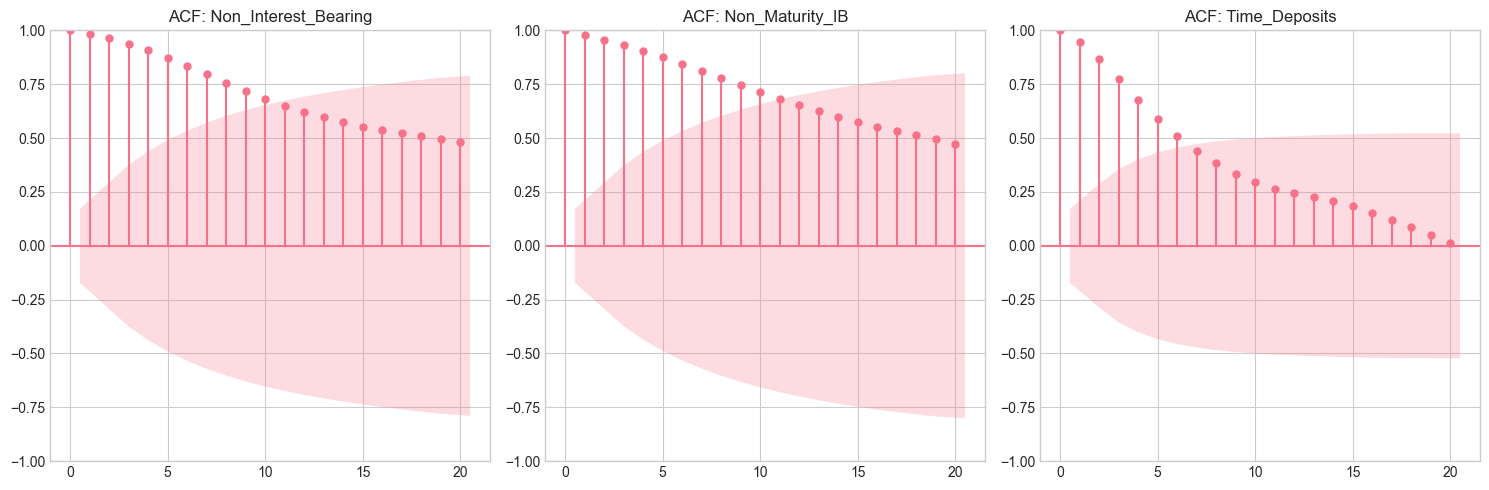

In [102]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']):
    plot_acf(merged_historic[col].dropna(), ax=axes[i], lags=20)  # Adjust lags as needed
    axes[i].set_title(f'ACF: {col}')
plt.tight_layout()
plt.savefig('plots/acf_plots.png', dpi=300, bbox_inches='tight')
plt.show()

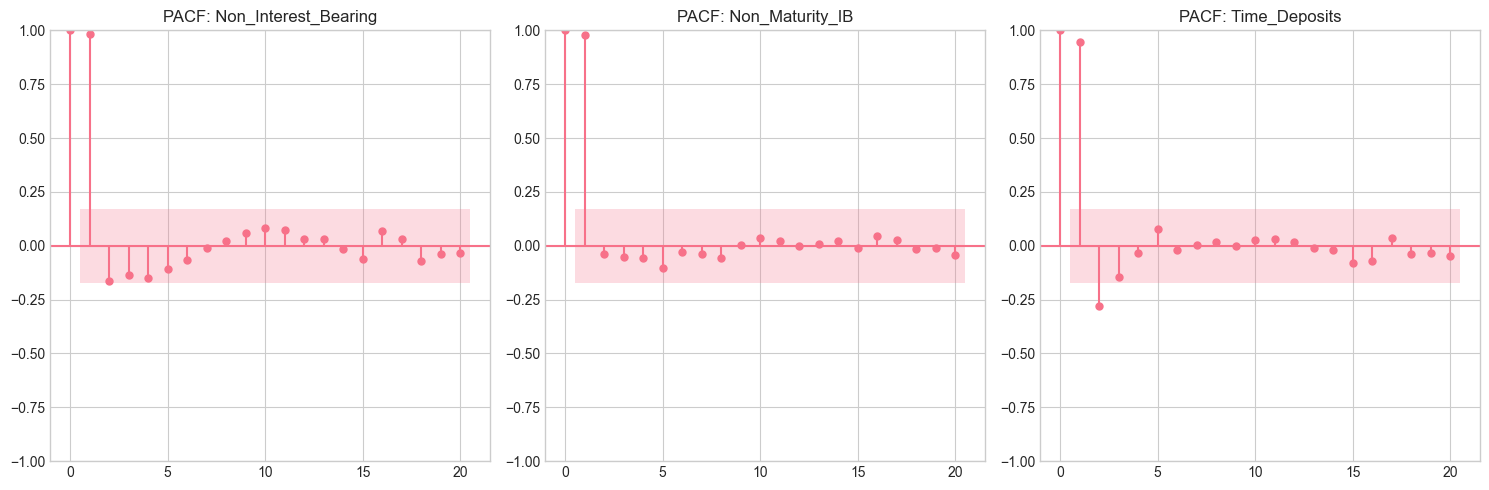

In [103]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']):
    plot_pacf(merged_historic[col].dropna(), ax=axes[i], lags=20)  # Adjust lags as needed
    axes[i].set_title(f'PACF: {col}')
plt.tight_layout()
plt.savefig('plots/pacf_plots.png', dpi=300, bbox_inches='tight')
plt.show()

In [64]:
print("\n=== STATISTICAL TESTS ===")
for col in ['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits', 'Real GDP']:
    result = adfuller(merged_historic[col].dropna())
    print(f'ADF Test for {col}: Statistic={result[0]:.4f}, p-value={result[1]:.4f}')
    if result[1] > 0.05:
        print(f'  -> Non-stationary (consider differencing/logs)')


=== STATISTICAL TESTS ===
ADF Test for Non_Interest_Bearing: Statistic=3.2335, p-value=1.0000
  -> Non-stationary (consider differencing/logs)
ADF Test for Non_Maturity_IB: Statistic=5.6440, p-value=1.0000
  -> Non-stationary (consider differencing/logs)
ADF Test for Time_Deposits: Statistic=-3.0618, p-value=0.0295
ADF Test for Real GDP: Statistic=0.0285, p-value=0.9608
  -> Non-stationary (consider differencing/logs)


In [65]:
from scipy import stats

In [80]:
for col in ['Non_IB_Growth', 'Non_Mat_IB_Growth', 'Time_Growth']:
    non_na_series = merged_historic[col].dropna()
    z_scores = np.abs(stats.zscore(non_na_series))
    outliers = non_na_series.index[z_scores > 3].tolist()
    print(f'Outliers in {col} (Z>3): {outliers[:5]}...')

Outliers in Non_IB_Growth (Z>3): [Timestamp('2020-06-30 00:00:00')]...
Outliers in Non_Mat_IB_Growth (Z>3): [Timestamp('2008-09-30 00:00:00'), Timestamp('2020-06-30 00:00:00')]...
Outliers in Time_Growth (Z>3): [Timestamp('2022-12-31 00:00:00'), Timestamp('2023-03-31 00:00:00'), Timestamp('2023-06-30 00:00:00')]...


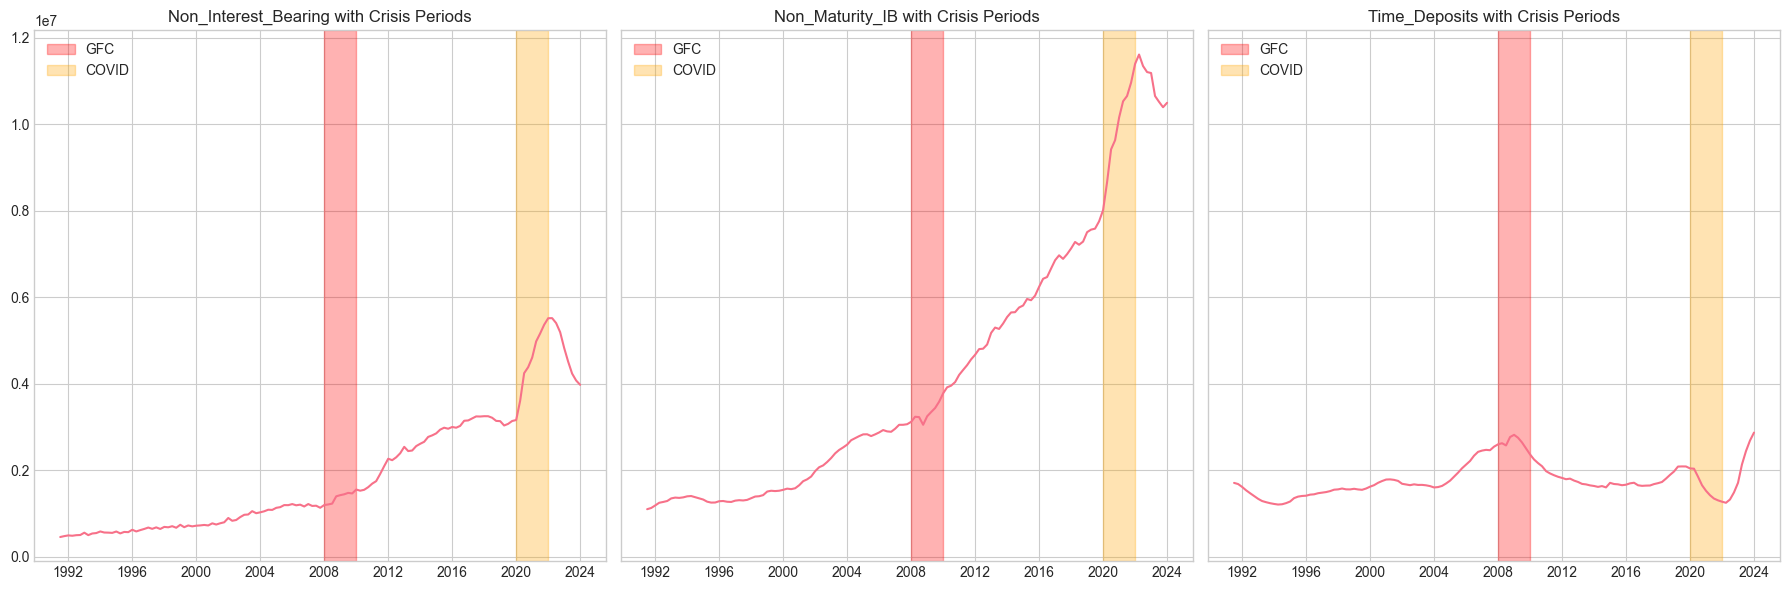

In [104]:
merged_historic['GFC_Dummy'] = ((merged_historic.index >= '2008-01-01') & (merged_historic.index <= '2009-12-31')).astype(int)
merged_historic['COVID_Dummy'] = ((merged_historic.index >= '2020-01-01') & (merged_historic.index <= '2021-12-31')).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for i, dep in enumerate(['Non_Interest_Bearing', 'Non_Maturity_IB', 'Time_Deposits']):
    axes[i].plot(merged_historic.index, merged_historic[dep])
    axes[i].axvspan('2008-01-01', '2009-12-31', color='red', alpha=0.3, label='GFC')
    axes[i].axvspan('2020-01-01', '2021-12-31', color='orange', alpha=0.3, label='COVID')
    axes[i].legend()
    axes[i].set_title(f'{dep} with Crisis Periods')
plt.tight_layout()
plt.savefig('plots/crisis_shading.png', dpi=300, bbox_inches='tight')
plt.show()


=== SCENARIO PREVIEW ===
Baseline GDP Growth Projections:
Date
2024-03-31    1.0
2024-06-30    0.7
2024-09-30    0.9
2024-12-31    1.5
2025-03-31    1.8
2025-06-30    2.0
2025-09-30    2.1
2025-12-31    2.1
2026-03-31    2.1
2026-06-30    2.0
Name: Real GDP growth, dtype: float64


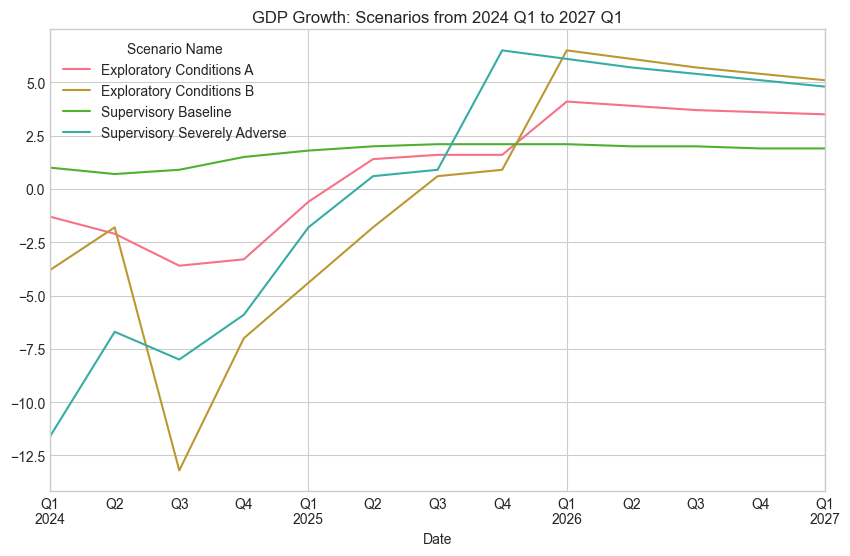

In [105]:
print("\n=== SCENARIO PREVIEW ===")
print("Baseline GDP Growth Projections:")
print(baseline_scen['Real GDP growth'].head(10))

scen_pivot = scenarios['Real GDP growth'].unstack(level='Scenario Name')
scen_pivot.plot(figsize=(10, 6), title='GDP Growth: Scenarios from 2024 Q1 to 2027 Q1')
plt.savefig('plots/scenario_gdp.png', dpi=300, bbox_inches='tight')
plt.show()